In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error,r2_score,root_mean_squared_error

In [3]:
housing=fetch_california_housing()
df=pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)

df["Median_House_Value"] = housing.target

print(df.head())
print("Dataset shape: ",df.shape)
print(df.info())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  Median_House_Value  
0    -122.23               4.526  
1    -122.22               3.585  
2    -122.24               3.521  
3    -122.25               3.413  
4    -122.25               3.422  
Dataset shape:  (20640, 9)
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   MedInc              20640 non-null  float64
 1   HouseAge            20640 non-null  float64
 2   AveRooms

In [4]:
#Select feature
x = df[["MedInc"]]
y = df["Median_House_Value"]

print("feature shape: ",x.shape)
print("target shape: ",y.shape)

feature shape:  (20640, 1)
target shape:  (20640,)


In [12]:
#train and test with diff training data sizes
#Model 1:25%
x_train1,x_test,y_train1,y_test=train_test_split(
    x,y,random_state=42,test_size=0.2,
    train_size=0.25
)

l1=LinearRegression()
l1.fit(x_train1,y_train1)
y_pred1=l1.predict(x_test)

#evaluation

mse_l1=mean_squared_error(y_test,y_pred1)
rmse_l1=mean_squared_error(y_test,y_pred1)
r2_l1=mean_squared_error(y_test,y_pred1)

#display the result

print("Evaluation Measures of Model with 25% Training Data")
print("-"*50)
print("MSE:",mse_l1)
print("RMSE:", rmse_l1)
print("R2 Score:", r2_l1)



Evaluation Measures of Model with 25% Training Data
--------------------------------------------------
MSE: 0.7092457070391448
RMSE: 0.7092457070391448
R2 Score: 0.7092457070391448


In [13]:
x_train2,x_test,y_train2,y_test=train_test_split(
    x,y,random_state=42,test_size=0.2,train_size=0.50
)

l2=LinearRegression()
l2.fit(x_train2,y_train2)
y_pred2=l2.predict(x_test)

# Model 2
mse_l2 = mean_squared_error(y_test, y_pred2)
rmse_l2 = root_mean_squared_error(y_test, y_pred2)
r2_l2 = r2_score(y_test, y_pred2)

print("\nEvaluation Measures of Model with 50% Training Data")
print("-" * 50)
print("MSE:", mse_l2)
print("RMSE:", rmse_l2)
print("R2 Score:", r2_l2)




Evaluation Measures of Model with 50% Training Data
--------------------------------------------------
MSE: 0.7091196786916377
RMSE: 0.8420924407044856
R2 Score: 0.4588562117121908


In [15]:
# Model 3: 75% Training Data
x_train3, x_test, y_train3, y_test = train_test_split(
    x, y, train_size=0.75, test_size=0.2, random_state=42
)

l3 = LinearRegression()
l3.fit(x_train3, y_train3)
y_pred3 = l3.predict(x_test)

mse_l3 = mean_squared_error(y_test, y_pred3)
rmse_l3 = root_mean_squared_error(y_test, y_pred3)
r2_l3 = r2_score(y_test, y_pred3)

print("\nEvaluation Measures of Model with 75% Training Data")
print("-" * 50)
print("MSE:", mse_l3)
print("RMSE:", rmse_l3)
print("R2 Score:", r2_l3)



Evaluation Measures of Model with 75% Training Data
--------------------------------------------------
MSE: 0.7091068016170301
RMSE: 0.842084794790305
R2 Score: 0.45886603847224927


In [20]:
print("Training samples in Model 1:", len(x_train1))
print("Training samples in Model 2:", len(x_train2))
print("Training samples in Model 3:", len(x_train3))
print("Testing samples:", len(x_test))

Training samples in Model 1: 5160
Training samples in Model 2: 10320
Training samples in Model 3: 15480
Testing samples: 4128


In [22]:
comparison=pd.DataFrame({
    "Models":["l1(25%)","l2(50%)","l3(75%)"],
    "Training Samples":[
        len(x_train1),
        len(x_train2),
        len(x_train3)
    ],
    "MSE":[mse_l1,mse_l2,mse_l3],
    "RMSE":[rmse_l1,rmse_l2,rmse_l3],
    "R2":[r2_l1,r2_l2,r2_l3]
})
print(comparison.round(4))

    Models  Training Samples     MSE    RMSE      R2
0  l1(25%)              5160  0.7092  0.7092  0.7092
1  l2(50%)             10320  0.7091  0.8421  0.4589
2  l3(75%)             15480  0.7091  0.8421  0.4589


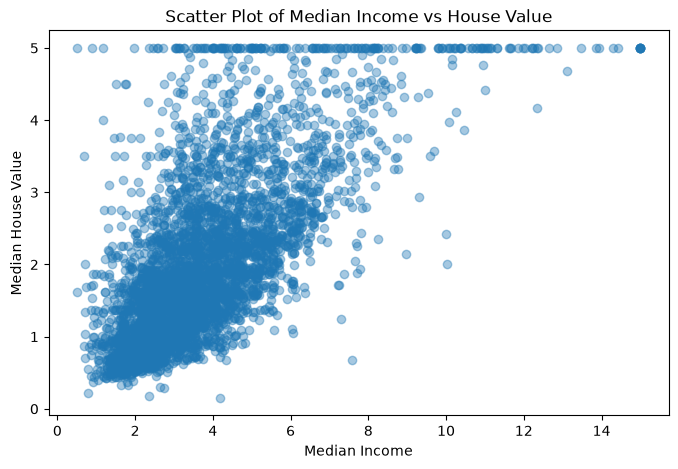

In [23]:
#Scatter plot
plt.figure(figsize=(8,5))

plt.scatter(x_test["MedInc"],y_test,alpha=0.4)
plt.title("Scatter Plot of Median Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

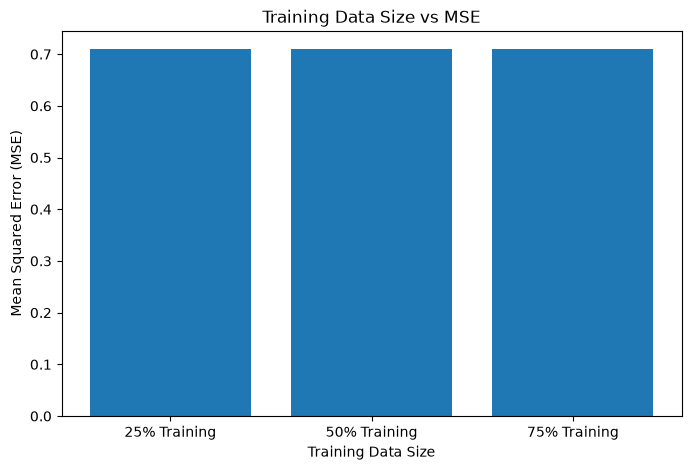

In [24]:
#  Training Data Size vs MSE

models = ["25% Training", "50% Training", "75% Training"]
mse_values = [mse_l1, mse_l2, mse_l3]

plt.figure(figsize=(8, 5))

plt.bar(models, mse_values)

plt.title("Training Data Size vs MSE")
plt.xlabel("Training Data Size")
plt.ylabel("Mean Squared Error (MSE)")

plt.show()

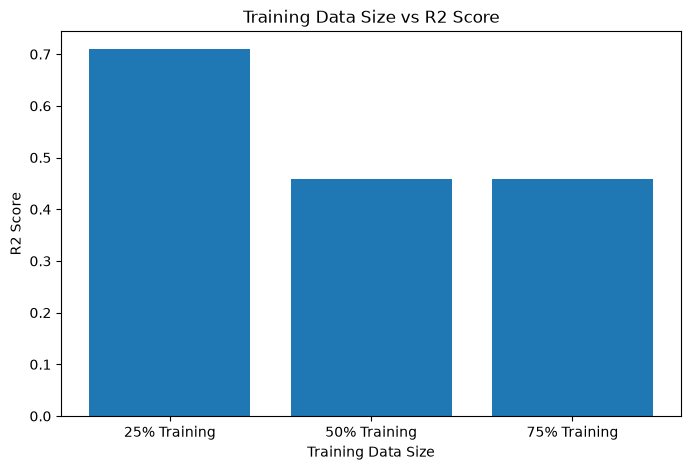

In [25]:
#  Training Data Size vs R2 Score

r2_values = [r2_l1, r2_l2, r2_l3]

plt.figure(figsize=(8, 5))

plt.bar(models, r2_values)

plt.title("Training Data Size vs R2 Score")
plt.xlabel("Training Data Size")
plt.ylabel("R2 Score")

plt.show()

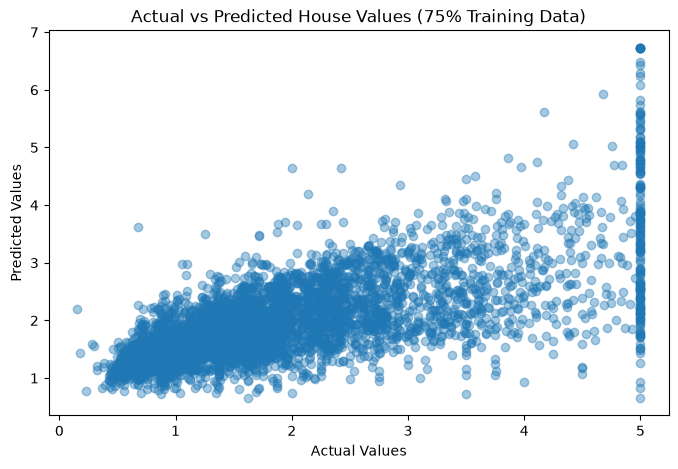

In [27]:
#  Compare Actual and Predicted Values

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred3, alpha=0.4)

plt.title("Actual vs Predicted House Values (75% Training Data)")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

plt.show()

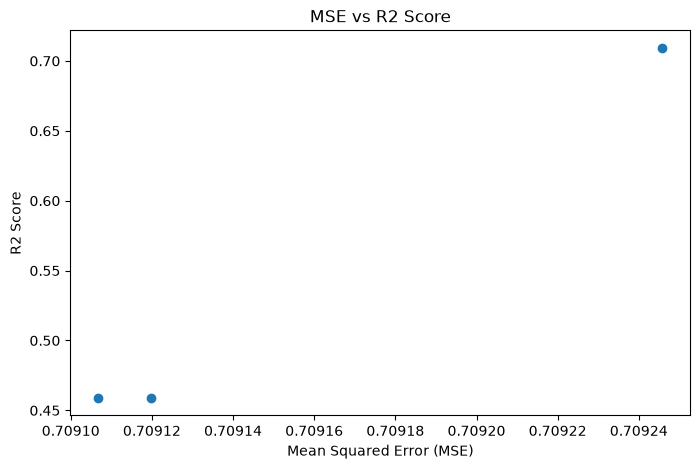

In [28]:
# MSE vs R2 Score Plot

mse_values = [mse_l1, mse_l2, mse_l3]
r2_values = [r2_l1, r2_l2, r2_l3]

plt.figure(figsize=(8, 5))

plt.scatter(mse_values, r2_values)

plt.title("MSE vs R2 Score")
plt.xlabel("Mean Squared Error (MSE)")
plt.ylabel("R2 Score")

plt.show()

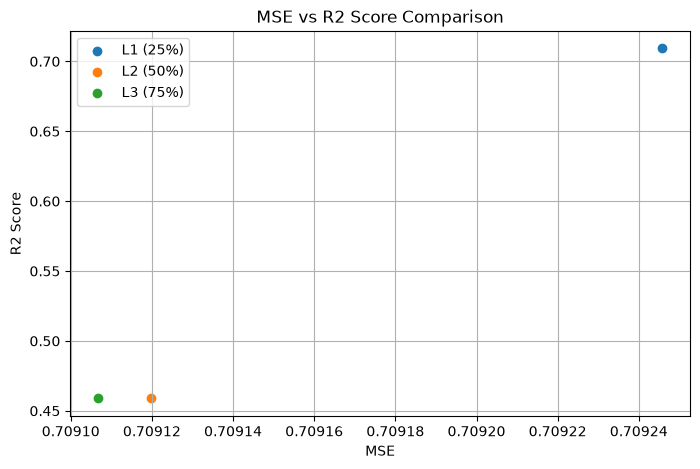

In [29]:
# MSE vs R2 Score Comparison

models = ["L1 (25%)", "L2 (50%)", "L3 (75%)"]

mse_values = [mse_l1, mse_l2, mse_l3]
r2_values = [r2_l1, r2_l2, r2_l3]

plt.figure(figsize=(8, 5))

for i in range(3):
    plt.scatter(mse_values[i], r2_values[i], label=models[i])

plt.title("MSE vs R2 Score Comparison")
plt.xlabel("MSE")
plt.ylabel("R2 Score")
plt.legend()
plt.grid(True)

plt.show()